<a href="https://colab.research.google.com/github/riasachdeva/riasachdeva.github.io/blob/main/Linear_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Linear Regression**

The dataset contains data from a study of lung function among a sample of 636 children aged 7 to 10 years living in a deprived suburb of Lima, Peru (introduced on page 27 of Kirkwood and Sterne)

**FEV1** is the forced expiratory volume in 1 second, the maximum amount of air which children could breath out in 1 second measured using a spirometer.

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
df = pd.read_excel('/content/Discussion Data Table .xlsx')

In [5]:
print(df.head(3))

   id  fev1    age  height  sex  respsymptoms
0   1  1.56  9.593   124.8    0             0
1   2  1.18  7.491   111.0    1             0
2   3  1.87  9.864   135.7    0             0


In [9]:
df.describe()

,id,fev1,age,height,sex,respsymptoms
count,636.000000,636.000000,636.000000,636.000000,636.000000,636.000000
mean,319.761006,1.594654,8.983753,124.052987,0.473270,0.227987
std,184.487704,0.304451,0.719409,6.237911,0.499678,0.419865
min,1.000000,0.640000,7.116000,105.600000,0.000000,0.000000
25%,160.750000,1.397500,8.493000,119.900000,0.000000,0.000000
50%,319.500000,1.580000,8.909000,124.000000,0.000000,0.000000
75%,479.250000,1.790000,9.627500,128.000000,1.000000,0.000000
max,638.000000,2.690000,10.440000,149.000000,1.000000,1.000000


In [6]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 636 entries, 0 to 635
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   id            636 non-null    int64  
 1   fev1          636 non-null    float64
 2   age           636 non-null    float64
 3   height        636 non-null    float64
 4   sex           636 non-null    int64  
 5   respsymptoms  636 non-null    int64  
dtypes: float64(3), int64(3)
memory usage: 29.9 KB
None


In [10]:
df.isnull().sum()

,0
id,0
fev1,0
age,0
height,0
sex,0
respsymptoms,0


# **Correlation Heatmap**

In [21]:
df_corr = df.drop(columns=['id'])

In [22]:
df_corr.head(3)

,fev1,age,height,sex,respsymptoms
0,1.56,9.593,124.8,0,0
1,1.18,7.491,111.0,1,0
2,1.87,9.864,135.7,0,0


In [23]:
correlation_matrix = df_corr.corr()

In [24]:
print(correlation_matrix)

                  fev1       age    height       sex  respsymptoms
fev1          1.000000  0.516166  0.637610  0.195124     -0.206291
age           0.516166  1.000000  0.594601 -0.033293     -0.174012
height        0.637610  0.594601  1.000000  0.006846     -0.100284
sex           0.195124 -0.033293  0.006846  1.000000     -0.034711
respsymptoms -0.206291 -0.174012 -0.100284 -0.034711      1.000000


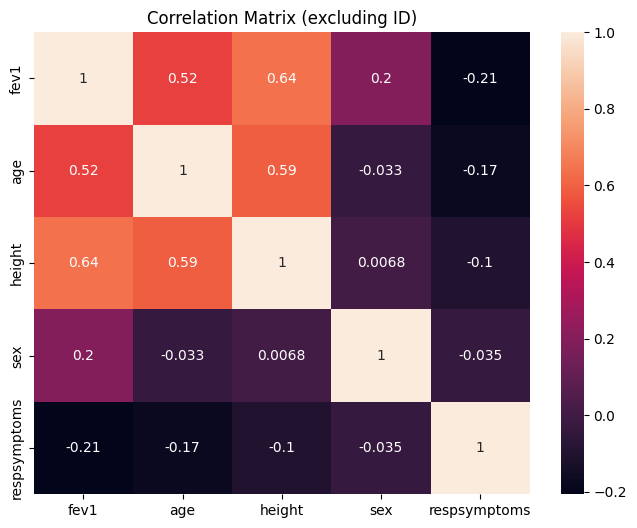

In [27]:
plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True)
plt.title("Correlation Matrix (excluding ID)")
plt.show()

# **How do age, height, sex, and respiratory symptoms impact lung function (FEV1)?**

## **Simple Linear Regression - Age**

In [37]:
from sklearn.linear_model import LinearRegression

In [54]:
X_age = df[['age']]
y = df['fev1']

In [58]:
model_age = LinearRegression()
model_age.fit(X_age, y)

print("Coefficient:", model_age.coef_[0])
print("Intercept:", model_age.intercept_)
print("R2 score:", model_age.score(X_age, y))

Coefficient: 0.21843942521298673
Intercept: -0.3677517851232863
R2 score: 0.2664270822802004


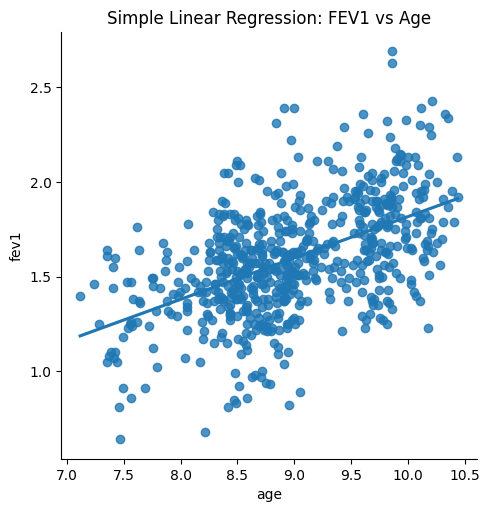

In [59]:
sns.lmplot(x='age', y='fev1', data=df, ci=None)
plt.title('Simple Linear Regression: FEV1 vs Age')
plt.show()

## **Simple Linear Regression - Height**

In [60]:
X_height = df[['height']]
y = df['fev1']

model_height = LinearRegression()
model_height.fit(X_height, y)

print("Coefficient:", model_height.coef_[0])
print("Intercept:", model_height.intercept_)
print("R2 score:", model_height.score(X_height, y))

Coefficient: 0.031119536371018938
Intercept: -2.265817365942989
R2 score: 0.40654599717242923


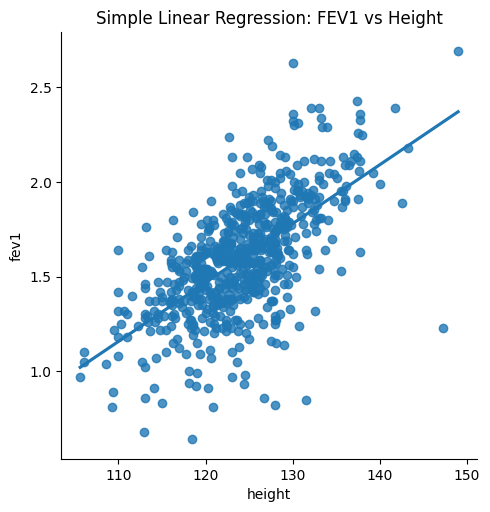

In [62]:
sns.lmplot(x='height', y='fev1', data=df, ci=None)
plt.title('Simple Linear Regression: FEV1 vs Height')
plt.show()

# **Multiple Linear Regression - Age and Height**

In [65]:
X = df[['age', 'height']]
y = df['fev1']

In [66]:
model = LinearRegression()
model.fit(X, y)

LinearRegression()

In [67]:
print(model.coef_, model.intercept_)

[0.08971429 0.02496743] -2.3086008422924467


In [68]:
r2 = model.score(X, y)
r2

0.43559785403750273

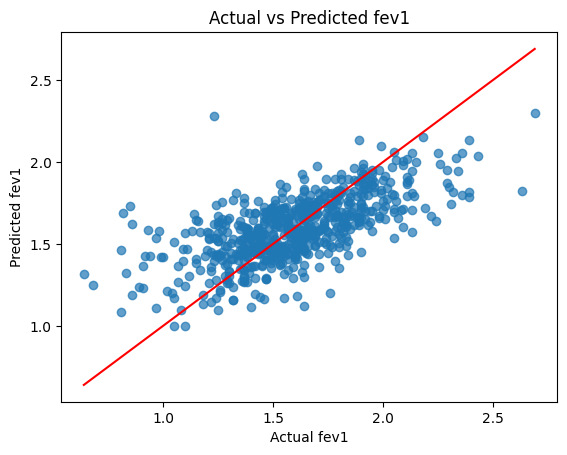

In [69]:
y_pred = model.predict(X)

plt.scatter(y, y_pred, alpha=0.7)
plt.plot([y.min(), y.max()], [y.min(), y.max()], color='red')  # ideal line
plt.xlabel("Actual fev1")
plt.ylabel("Predicted fev1")
plt.title("Actual vs Predicted fev1")
plt.show()